# SARSA: Safe Paths on the Cliff

**Family:** Reinforcement learning | **Level:** Intermediate | **Dataset:** `CliffWalking-v1` | **Runs on:** CPU, about 1 minute(s)

Learn the value of the policy you actually follow, including its exploration.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- On policy TD control
- How exploration changes the learned path
- Comparing the online return with the greedy return
- Why SARSA picks the safer route

**Prerequisites:**

- Probability basics
- Markov decision processes

**Skills you will have afterwards:**

- Run several seeds
- Report learning curves with spread
- Compare with a baseline policy

## 2. Real-World Problem

**Context.** A robot walks along a cliff edge. A fall costs a lot and sends it back to the start.

**The problem.** Learn a route from start to goal when exploratory moves may fall off the cliff.

**Why it matters.** When mistakes are costly during learning, the learning rule decides how careful the agent is.

**Why machine learning.** The agent has no model of the grid.

**Why this algorithm.** SARSA accounts for exploration in its updates.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Reinforcement Learning: An Introduction (2nd ed.)

- **Type:** foundational paper
- **Authors:** Sutton, R. S. and Barto, A. G.
- **Year and venue:** 2018, MIT Press
- **DOI or URL:** http://incompleteideas.net/book/the-book-2nd.html
- **Verification:** not verified in build environment
- **Research objective:** Textbook covering dynamic programming, Monte Carlo, TD, policy gradient.
- **Methodology:** Textbook.
- **Dataset:** Not applicable.
- **Main findings:** Reference text for this section.
- **Limitations:** Textbook, not an experiment.

### Learning to predict by the methods of temporal differences

- **Type:** foundational paper
- **Authors:** Sutton, R. S.
- **Year and venue:** 1988, Machine Learning 3(1):9-44
- **DOI or URL:** https://doi.org/10.1007/BF00115009
- **Verification:** Crossref 2026-11-17
- **Research objective:** Introduce temporal difference learning for prediction.
- **Methodology:** Update value estimates from the difference between successive predictions.
- **Dataset:** Random walk experiments.
- **Main findings:** TD methods learn faster than supervised updating on the random walk task.
- **Limitations:** Tabular and linear settings in the paper.

**Relationship to this notebook.** Sutton and Barto (not verified in the build environment) introduce the cliff walking comparison of SARSA and Q-learning. We run our own version. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Update.** After the quintuple $(S, A, R, S', A')$:

$$Q(S,A) \leftarrow Q(S,A) + \alpha\,[R + \gamma Q(S',A') - Q(S,A)]$$

**On policy.** $A'$ is the action the epsilon greedy policy will take, so the learned values include the cost of exploring.

**Convergence.** Tabular SARSA converges to the optimal policy if the policy becomes greedy in the limit and every pair is visited infinitely often.

## 5. Dataset Introduction

**CliffWalking-v1** (Gymnasium, `toy_text`): 4 by 12 grid, 48 states, 4 actions. Every step costs -1, stepping into the cliff costs -100 and returns to the start. The best path along the cliff edge has return -13. There is no dataset.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym
from IPython.display import display

from ml_lab.rl import tabular, deep
from ml_lab.evaluation import evaluate_policy
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "sarsa"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()
print("gymnasium", gym.__version__)

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
gymnasium 1.4.0


## 6. Exploratory Data Analysis

There is no dataset. We inspect the environment: observation and action spaces, rewards and a random policy baseline. 

In [2]:
env = gym.make("CliffWalking-v1")
print("observations:", env.observation_space, "| actions:", env.action_space)
print("start state:", env.reset(seed=0)[0], "| goal state: 47 | cliff states: 37 to 46")

observations: Discrete(48) | actions: Discrete(4)
start state: 36 | goal state: 47 | cliff states: 37 to 46


## 7. Data Preprocessing

Same settings for SARSA and Q-learning: step size 0.5, discount 1, epsilon 0.1, 500 episodes, 10 seeds. Greedy evaluation uses the Q table without exploration.

In [3]:
EPISODES, SEEDS = 500, range(10)
def greedy_return(q, max_steps=200):
    env = gym.make("CliffWalking-v1")
    s, _ = env.reset(seed=0)
    total, path = 0, [s]
    for _ in range(max_steps):
        s, r, term, trunc, _ = env.step(int(q[s].argmax()))
        total += r; path.append(s)
        if term or trunc:
            break
    return total, path

## 8. Algorithm Implementation

### 8.1 Concept

The agent learns from what it really does. If exploring near the cliff sometimes ends in a fall, the values of cliff edge cells go down.

### 8.2 Python implementation from scratch

Source of the SARSA update in `ml_lab.rl.tabular`:

In [4]:
print(inspect.getsource(tabular.sarsa))

def sarsa(env_id, episodes, alpha=0.5, gamma=0.99, epsilon=0.1, seed=0, decay=None, **env_kwargs):
    """On policy TD control."""
    env = gym.make(env_id, **env_kwargs)
    rng = np.random.default_rng(seed)
    q = np.zeros((env.observation_space.n, env.action_space.n))
    returns = []
    env.reset(seed=seed)
    for ep in range(episodes):
        eps = epsilon if decay is None else max(0.01, epsilon * decay ** ep)
        state, _ = env.reset()
        action = epsilon_greedy(q[state], eps, rng)
        done, total = False, 0.0
        while not done:
            nxt, reward, term, trunc, _ = env.step(action)
            nxt_action = epsilon_greedy(q[nxt], eps, rng)
            target = reward + gamma * q[nxt, nxt_action] * (not term)
            q[state, action] += alpha * (target - q[state, action])
            state, action, total, done = nxt, nxt_action, total + reward, term or trunc
        returns.append(total)
    env.close()
    return q, np.array(returns)



### 8.3 Library implementation

The algorithm is implemented in `src/ml_lab/rl` without an RL library. Gymnasium supplies only the environment.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `alpha` | Step size. |
| `gamma` | Discount. |
| `epsilon` | Exploration rate. |

## 9. Model Training

Train SARSA and Q-learning with 10 seeds each.

In [5]:
runs = {}
for name, fn in [("SARSA", tabular.sarsa), ("Q-learning", tabular.q_learning)]:
    runs[name] = [fn("CliffWalking-v1", EPISODES, alpha=0.5, gamma=1.0, epsilon=0.1, seed=s) for s in SEEDS]
for name, rs in runs.items():
    print(name, "| online return over last 100 episodes (mean over seeds):", round(float(np.mean([r[1][-100:].mean() for r in rs])), 1))

SARSA | online return over last 100 episodes (mean over seeds): -26.2
Q-learning | online return over last 100 episodes (mean over seeds): -47.5


## 10. Evaluation

Two numbers per method. Online return: the average reward while learning and exploring (last 100 episodes). Greedy return: reward of the final greedy path. SARSA is expected to have the higher online return and Q-learning the shorter greedy path. We check this, we do not assume it.

In [6]:
summary = {}
for name, rs in runs.items():
    online = np.array([r[1][-100:].mean() for r in rs])
    greedy = np.array([greedy_return(r[0])[0] for r in rs])
    summary[name] = dict(online_mean=online.mean(), online_std=online.std(ddof=1), greedy_mean=greedy.mean(), greedy_std=greedy.std(ddof=1))
display(pd.DataFrame(summary).T.round(2))
METRICS = {f"{k}_{n.lower().replace('-', '_')}": float(v) for n, d in summary.items() for k, v in d.items()}
CONFIG = {"alpha": 0.5, "gamma": 1.0, "epsilon": 0.1, "episodes": EPISODES, "seeds": 10}
EXTRA = {"optimal_return": -13}

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="reinforcement_learning", algorithm="SARSA", dataset="CliffWalking-v1",
                          task="control", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

,online_mean,online_std,greedy_mean,greedy_std
SARSA,-26.16,3.94,-54.0,76.95
Q-learning,-47.53,10.35,-13.0,0.00


saved: /home/claude/open-python/experiments/results/sarsa.json


,metric
online_mean_sarsa,-26.1630
online_std_sarsa,3.9402
greedy_mean_sarsa,-54.0000
greedy_std_sarsa,76.9531
online_mean_q_learning,-47.5340
online_std_q_learning,10.3522
greedy_mean_q_learning,-13.0000
greedy_std_q_learning,0.0000


## 11. Visualization

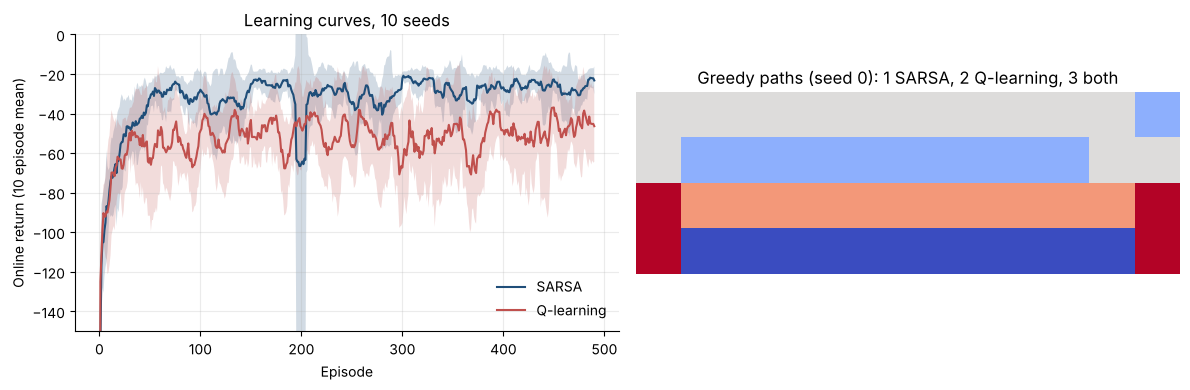

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, rs in runs.items():
    curves = np.array([np.convolve(r[1], np.ones(10) / 10, mode="valid") for r in rs])
    axes[0].plot(curves.mean(axis=0), label=name)
    axes[0].fill_between(range(curves.shape[1]), curves.mean(axis=0) - curves.std(axis=0), curves.mean(axis=0) + curves.std(axis=0), alpha=0.2)
axes[0].set_ylim(-150, 0); axes[0].set_xlabel("Episode"); axes[0].set_ylabel("Online return (10 episode mean)"); axes[0].legend(); axes[0].set_title("Learning curves, 10 seeds")
grid = np.zeros((4, 12))
for name, color in [("SARSA", 1), ("Q-learning", 2)]:
    _, path = greedy_return(runs[name][0][0])
    for s in path:
        grid[s // 12, s % 12] += color
grid[3, 1:11] = -1
axes[1].imshow(grid, cmap="coolwarm"); axes[1].set_title("Greedy paths (seed 0): 1 SARSA, 2 Q-learning, 3 both"); axes[1].axis("off")
plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "paths"); plt.show()

## 12. Interpretation

The SARSA path keeps a distance from the cliff because its values contain the cost of exploratory falls.

In [8]:
for name in runs:
    ret, path = greedy_return(runs[name][0][0])
    rows_used = sorted({s // 12 for s in path})
    print(f"{name}: greedy return {ret}, path length {len(path) - 1}, rows used {rows_used} (row 3 is the cliff edge row)")

SARSA: greedy return -17, path length 17, rows used [0, 1, 2, 3] (row 3 is the cliff edge row)
Q-learning: greedy return -13, path length 13, rows used [2, 3] (row 3 is the cliff edge row)


## 13. Experiments and Challenges

### Experiment 1: Exploration rate

Epsilon 0.01, 0.1 and 0.3 for SARSA, online and greedy return, 5 seeds.

In [9]:
for eps in [0.01, 0.1, 0.3]:
    rs = [tabular.sarsa("CliffWalking-v1", EPISODES, alpha=0.5, gamma=1.0, epsilon=eps, seed=s) for s in range(5)]
    print(f"epsilon={eps}: online {np.mean([r[1][-100:].mean() for r in rs]):.1f}, greedy {np.mean([greedy_return(r[0])[0] for r in rs]):.1f}")

epsilon=0.01: online -16.1, greedy -15.4


epsilon=0.1: online -28.1, greedy -17.4


epsilon=0.3: online -69.4, greedy -163.4


### Experiment 2: Decaying exploration

With epsilon decaying to 0.01 SARSA should approach the optimal edge path.

In [10]:
rs = [tabular.sarsa("CliffWalking-v1", 2000, alpha=0.5, gamma=1.0, epsilon=0.5, decay=0.995, seed=s) for s in range(5)]
print("greedy returns with decaying epsilon:", [greedy_return(r[0])[0] for r in rs], "(optimal -13)")

greedy returns with decaying epsilon: [-17, -17, -17, -17, -17] (optimal -13)


### Experiment 3: Step size

Alpha 0.1, 0.5, 0.9.

In [11]:
for a in [0.1, 0.5, 0.9]:
    rs = [tabular.sarsa("CliffWalking-v1", EPISODES, alpha=a, gamma=1.0, epsilon=0.1, seed=s) for s in range(5)]
    print(f"alpha={a}: online {np.mean([r[1][-100:].mean() for r in rs]):.1f}")

alpha=0.1: online -21.0


alpha=0.5: online -28.1


alpha=0.9: online -62.9


### Exercises for learners

1. Repeat with a different set of seeds and report the spread.
2. Change the discount factor and describe what happens to the learned behaviour.
3. Change one hyperparameter by a factor of 10 and compare learning curves.

## 14. Research Discussion

The textbook story is that SARSA learns the safer path and Q-learning the shorter one. The online and greedy numbers above test both halves of that statement on our runs.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Try expected SARSA and decaying epsilon, and compare with more seeds.

**Research limitations.** One dataset and one seed for the headline numbers. Few seeds (see the notebook), small environments, and no hyperparameter search beyond the experiments shown.

## 15. Summary and Further Reading

**Key takeaways**

- SARSA is on policy.
- Exploration enters the learned values.
- Report online and greedy returns separately.

**Use cases.** Tasks where exploration is costly.

**Limitations.** Tabular only.

**Recommended next notebook.** Q-learning.

**Further reading.** See `references.md` in this folder.